<a href="https://colab.research.google.com/github/vedikabhusari08/first_repo_vedika/blob/main/VedikaMLlab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vedika Bhusari C_C1_13

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.inspection import permutation_importance

In [ ]:
df=pd.read_csv("winequality-red.csv")

In [ ]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [ ]:
df.shape

(1599, 12)

In [ ]:
df.info

<bound method DataFrame.info of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.067   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                    11.0                  34.0  0.99780  3.51       0.56   
1                    25.0                  67.0  0.99680  3.20       0.68   
2                    15.0                  54.0  0.99700  3.26       0.65   
3                    17.0                  60.0  0.99800  3.16       0.58   
4                    11.0                  34.0  0.99780  3.51       0.56   
...                   ...                   ...      ...   ...        ...   
1594                 32.0                  44.0  0.99490  3.45       0.58   
1595                 39.0                  51.0  0.99512  3.52       0.76   
1596                 29.0                  40.0  0.99574  3.42       0.75   
1597                 32.0                  44.0  0.99547  3.57       0.71   
1598                 18.0                  42.0  0.99549  3.39       0.66   

      alcohol  quality  
0         9.4        5  
1         9.8        5  
2         9.8        5  
3         9.8        6  
4         9.4        5  
...       ...      ...  
1594     10.5        5  
1595     11.2        6  
1596     11.0        6  
1597     10.2        5  
1598     11.0        6  

[1599 rows x 12 columns]>

In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


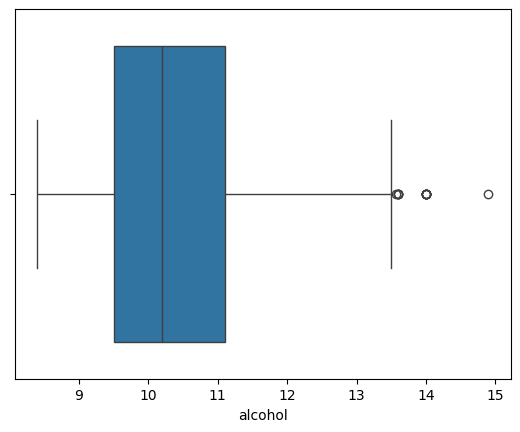

In [ ]:
sns.boxplot(x=df["alcohol"])
plt.show()

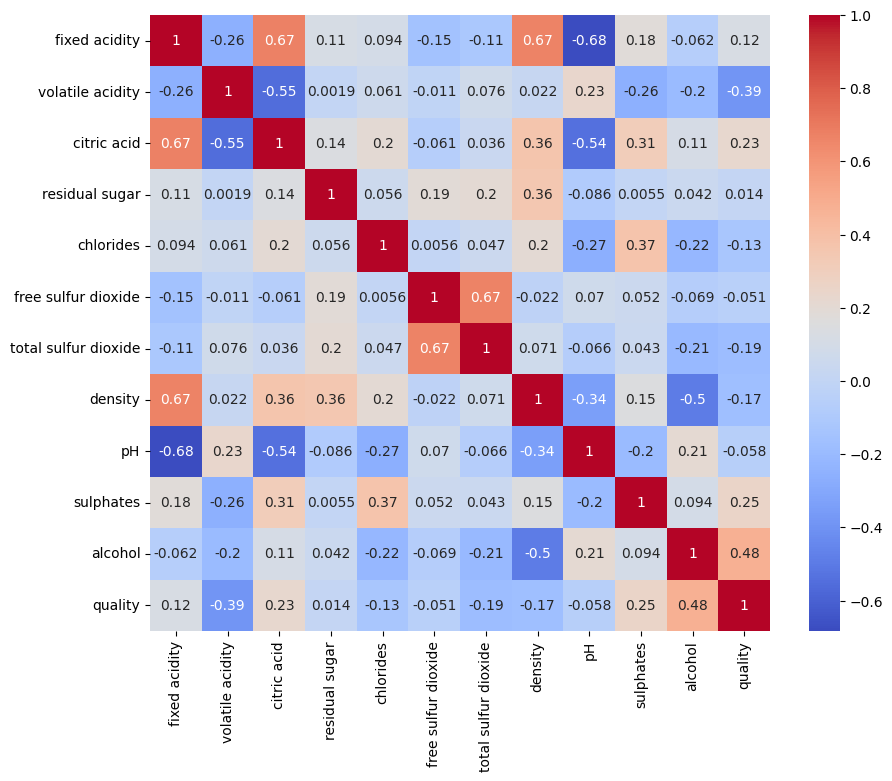

In [ ]:
plt.figure(figsize=(10,8))
numeric_df=df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(),annot=True,cmap='coolwarm')
plt.show()

<Axes: >

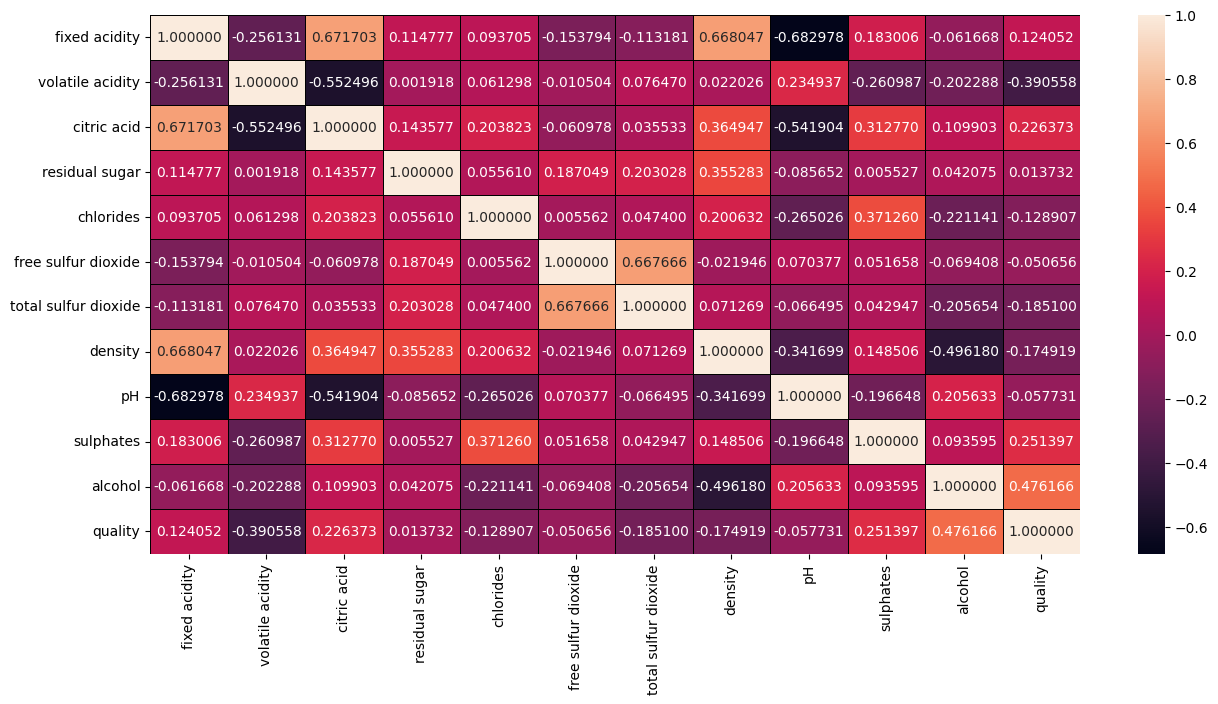

In [ ]:
plt.figure(figsize=(15,7))
sns.heatmap(df.corr(),annot=True, linewidths=0.5, linecolor="Black", fmt="2f")

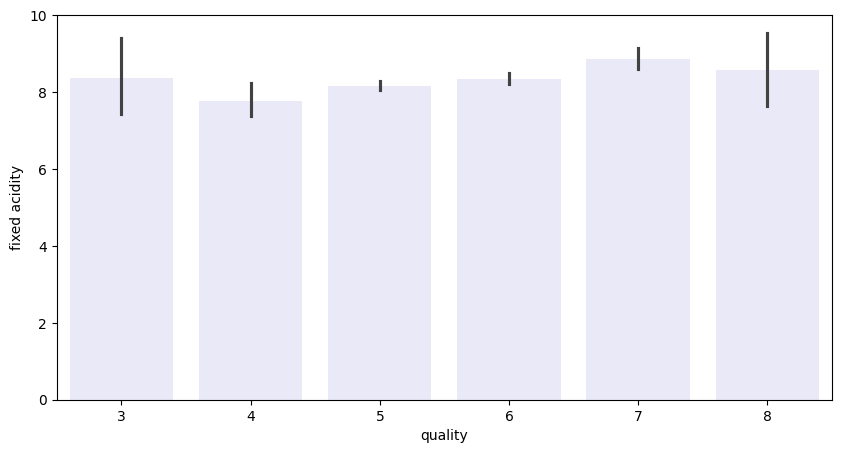

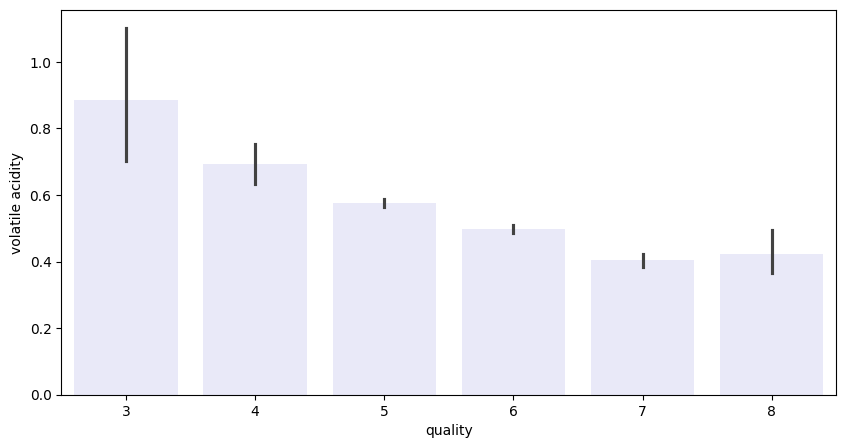

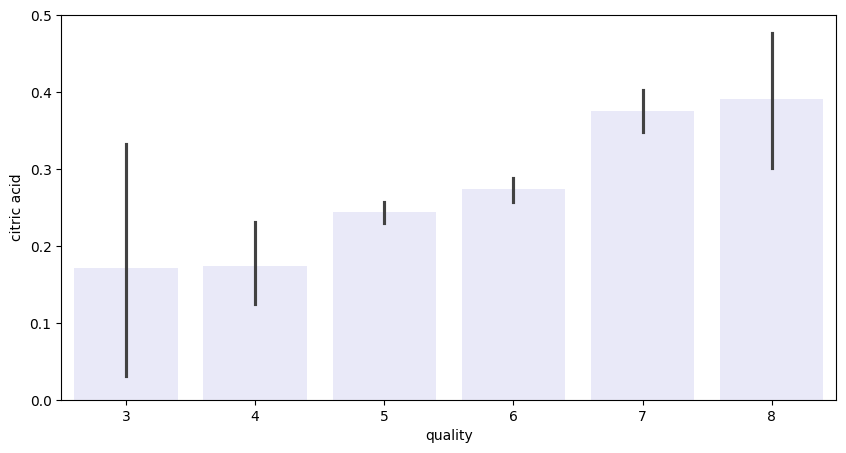

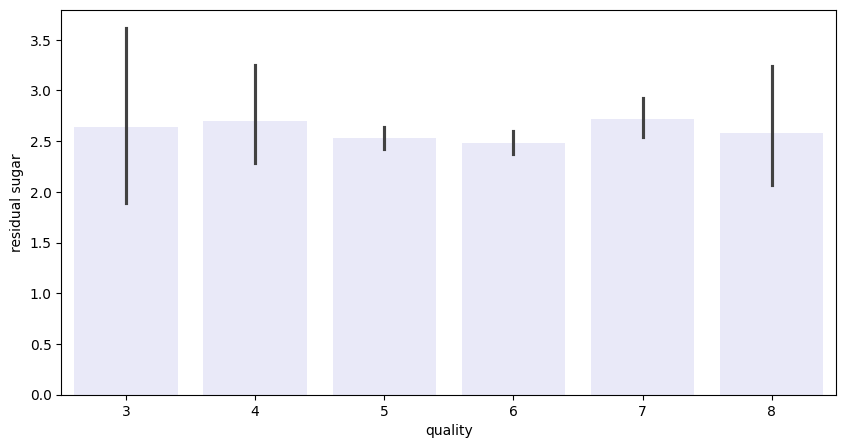

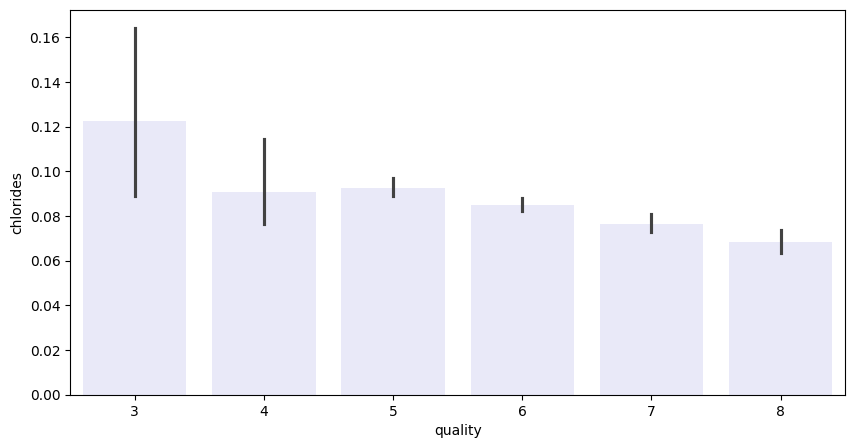

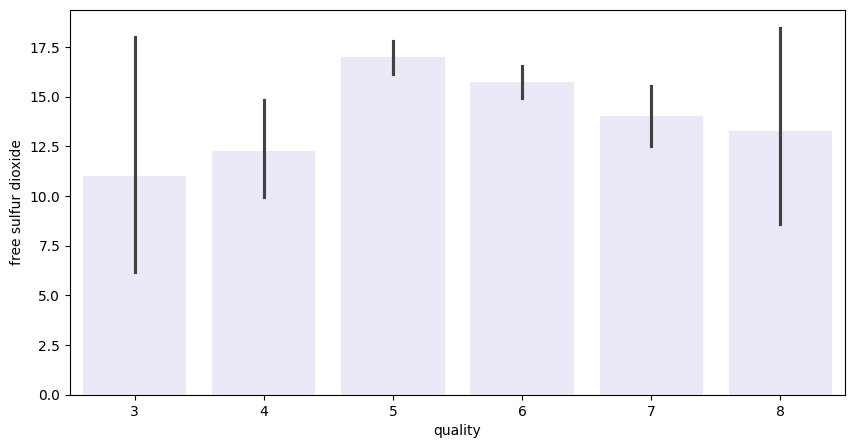

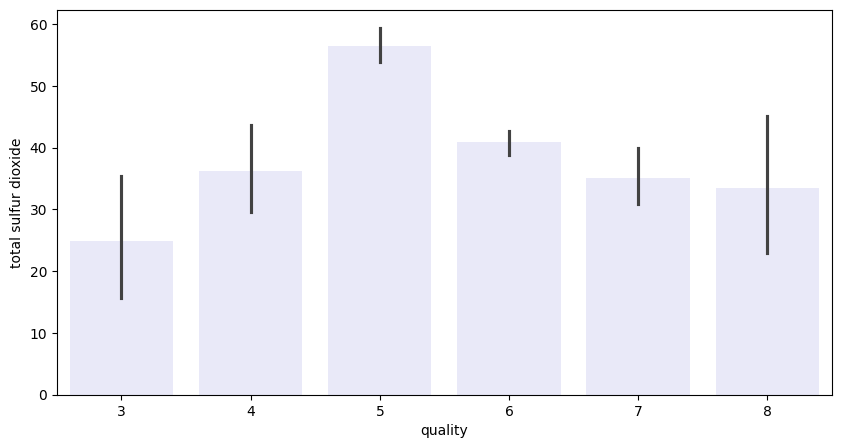

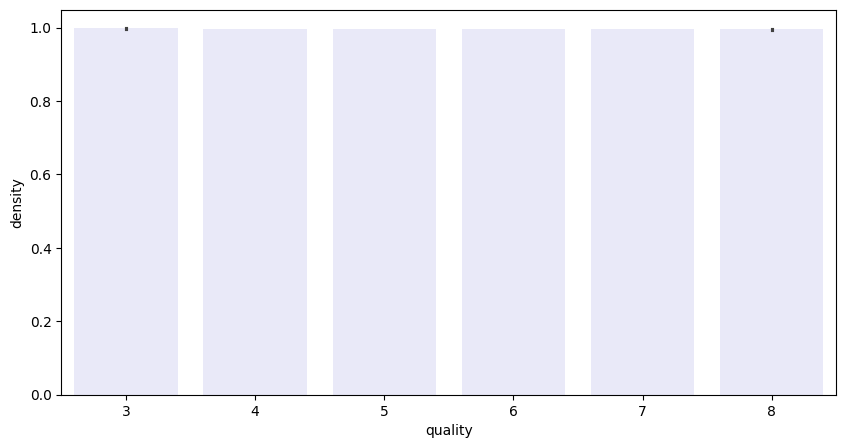

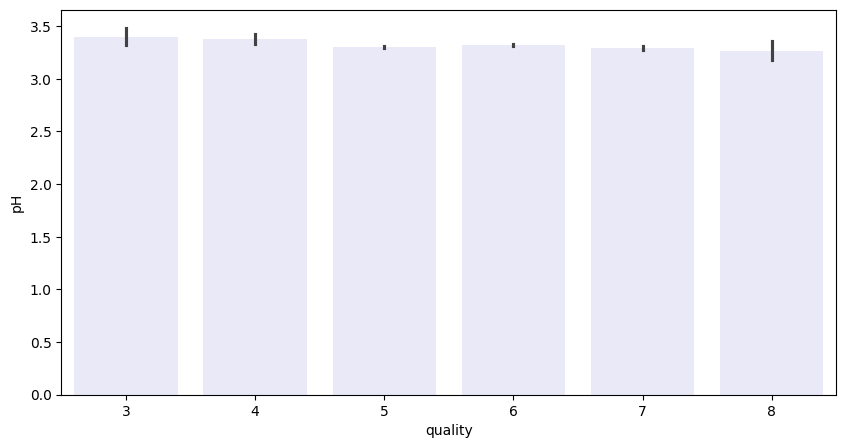

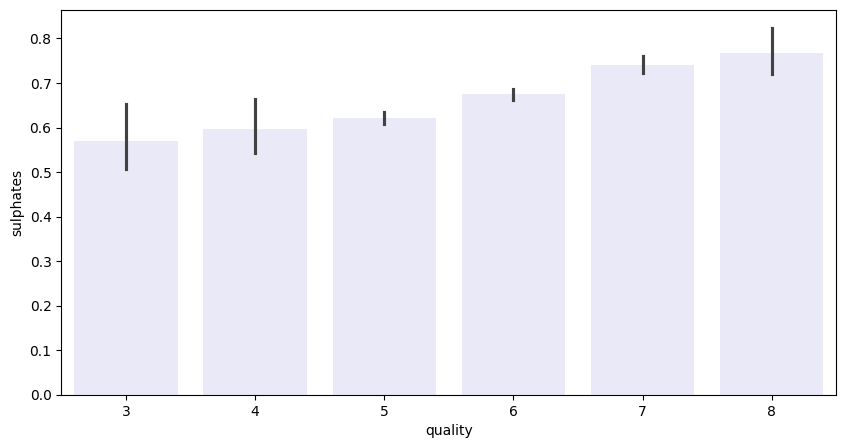

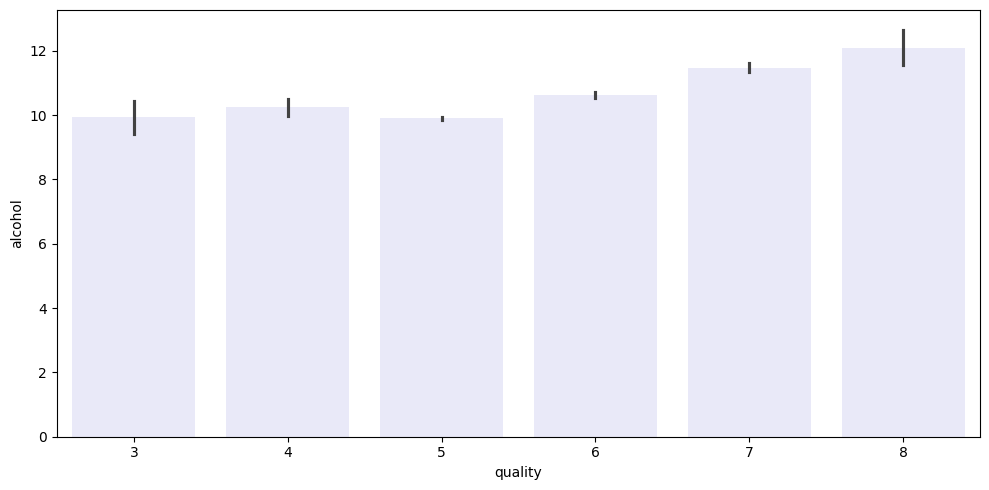

In [ ]:
index=0
labels=df['quality']
features=df.drop('quality',axis=1)

for col in features.items():
  plt.figure(figsize=(10,5))
  sns.barplot(x=labels,y=col[index],data=df,color="lavender")
plt.tight_layout()
plt.show()

In [ ]:
import warnings
warnings.filterwarnings('ignore')

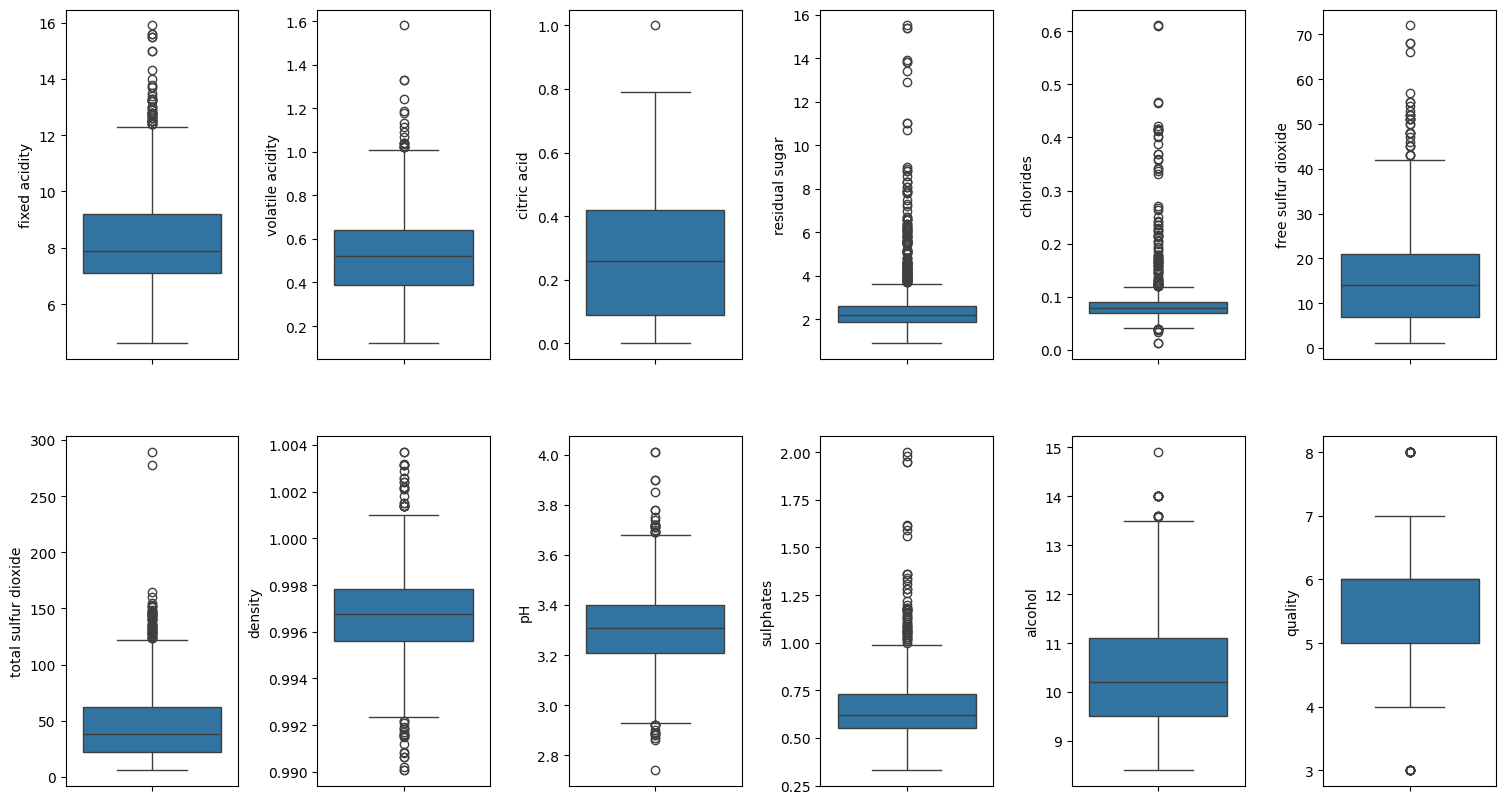

In [ ]:
features = df.drop(columns=["quality"])
fig, ax=plt.subplots(ncols=6, nrows=2, figsize=(15, 8))
index=0
ax=ax.flatten()
for col, value in df.items():
    sns.boxplot(y=col, data=df, ax=ax[index])
    index+=1
plt.tight_layout(pad=0.5, w_pad=0.7, h_pad=5.0)
plt.show()

<Axes: xlabel='citric acid', ylabel='quality'>

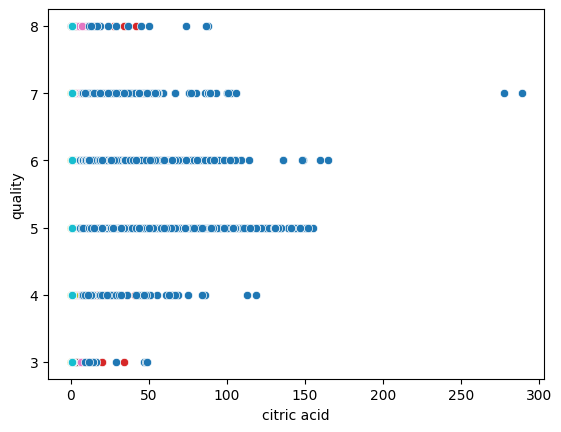

In [ ]:
sns.scatterplot(x='citric acid',y='quality',data=df)
sns.scatterplot(x='residual sugar',y='quality',data=df)
sns.scatterplot(x='chlorides',y='quality',data=df)
sns.scatterplot(x='free sulfur dioxide',y='quality',data=df)
sns.scatterplot(x='alcohol',y='quality',data=df)
sns.scatterplot(x='pH',y='quality',data=df)
sns.scatterplot(x='fixed acidity',y='quality',data=df)
sns.scatterplot(x='volatile acidity',y='quality',data=df)
sns.scatterplot(x='sulphates',y='quality',data=df)
sns.scatterplot(x='density',y='quality',data=df)
sns.scatterplot(x='total sulfur dioxide',y='quality',data=df)

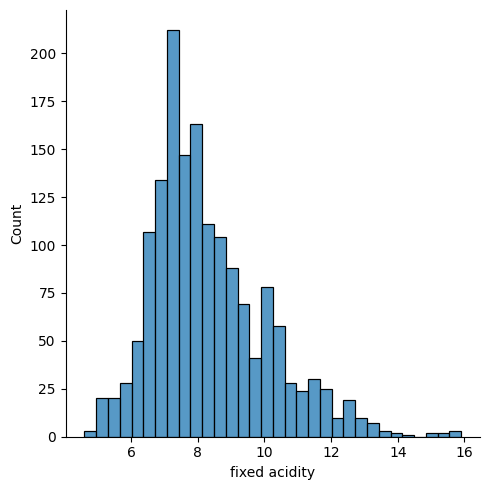

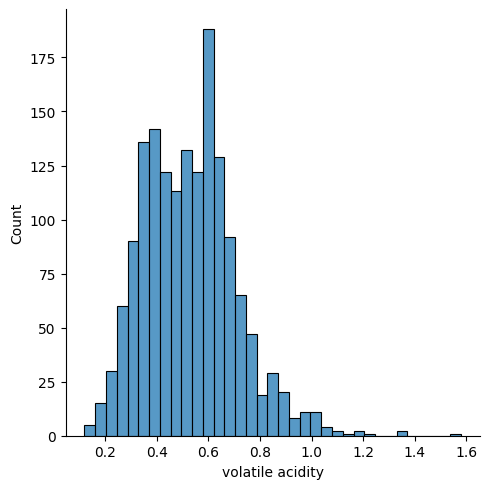

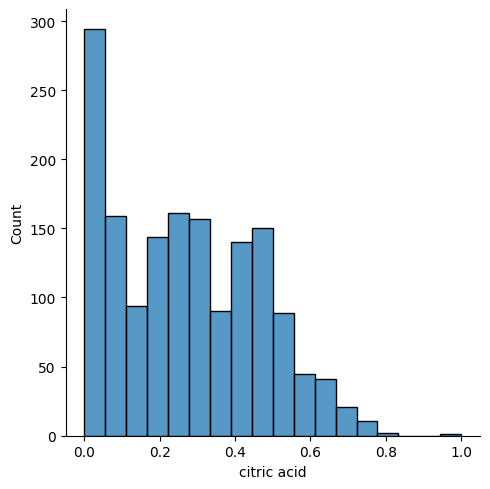

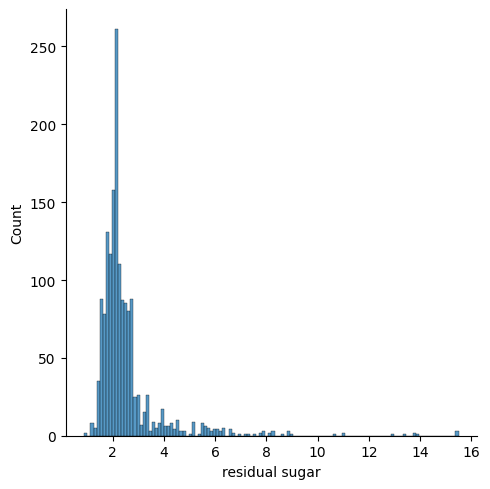

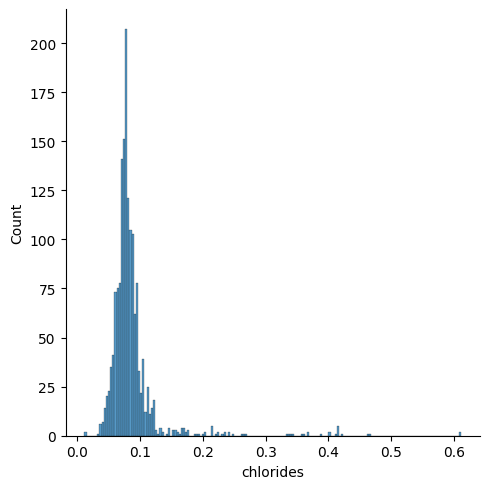

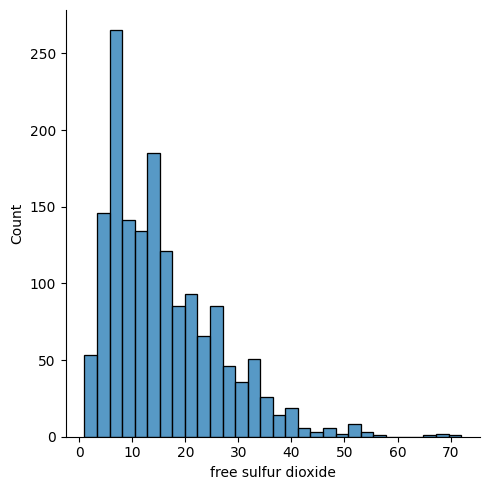

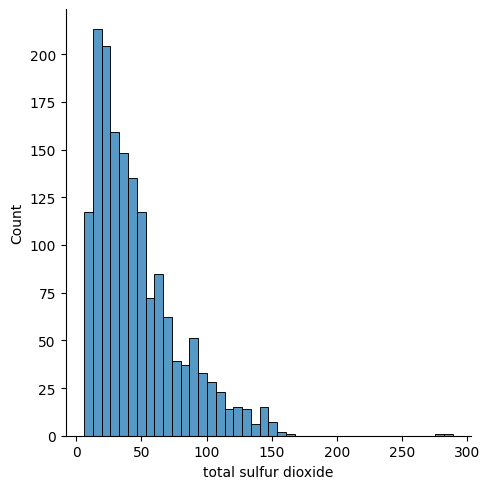

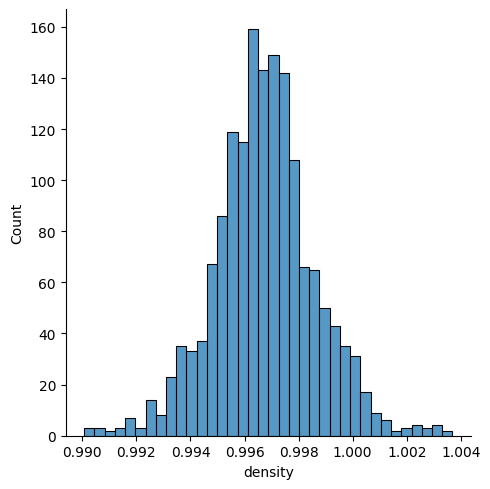

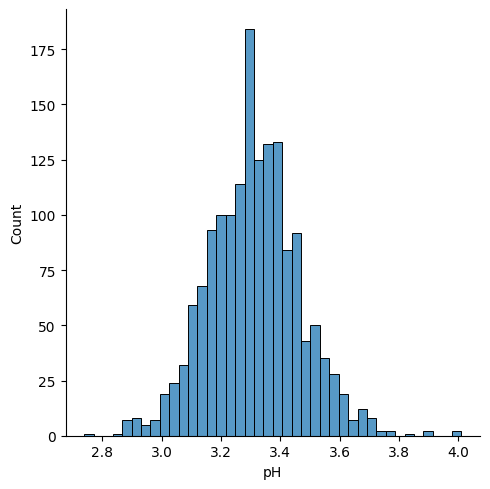

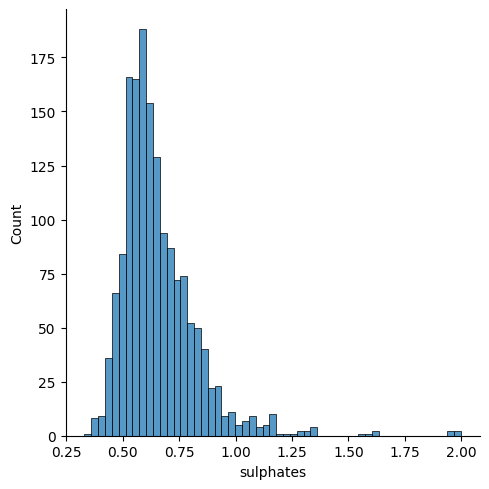

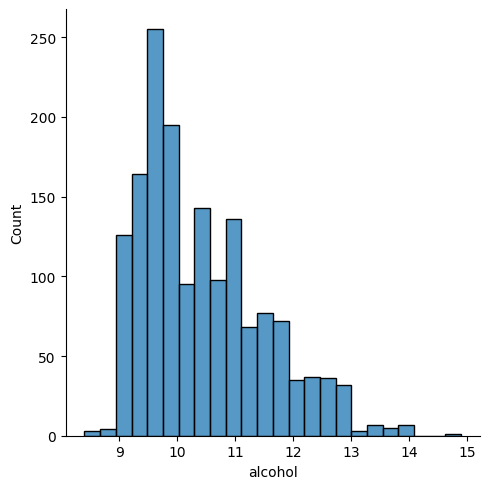

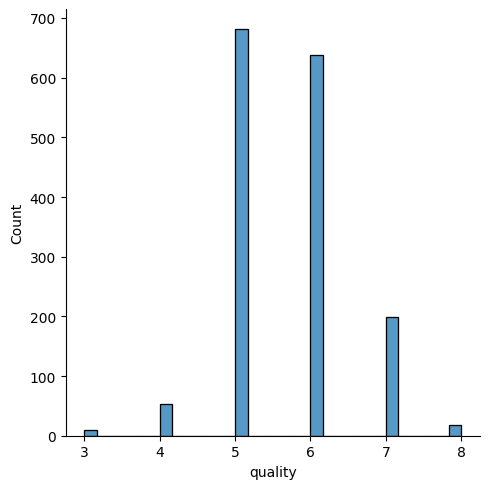

In [ ]:
sns.displot(df["fixed acidity"])
sns.displot(df["volatile acidity"])
sns.displot(df["citric acid"])
sns.displot(df["residual sugar"])
sns.displot(df["chlorides"])
sns.displot(df["free sulfur dioxide"])
sns.displot(df["total sulfur dioxide"])
sns.displot(df["density"])
sns.displot(df["pH"])
sns.displot(df["sulphates"])
sns.displot(df["alcohol"])
sns.displot(df["quality"])

In [ ]:
X=df.drop('quality',axis=1)
y=df['quality']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
results=[]

In [ ]:
def evaluate(name,model):
  model.fit(X_train,y_train)
  pred=model.predict(X_test)
  acc=accuracy_score(y_test,pred)
  print(name,acc)
  print(classification_report(y_test,pred))
  cm=confusion_matrix(y_test,pred)
  sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
  plt.title(name)
  plt.show()
  results.append([name,acc,model.get_depth(),model.tree_.node_count])
  return model

Origianl 0.59375
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.11      0.09      0.10        11
           5       0.66      0.64      0.65       136
           6       0.58      0.62      0.60       128
           7       0.53      0.53      0.53        40
           8       0.50      0.33      0.40         3

    accuracy                           0.59       320
   macro avg       0.40      0.37      0.38       320
weighted avg       0.59      0.59      0.59       320



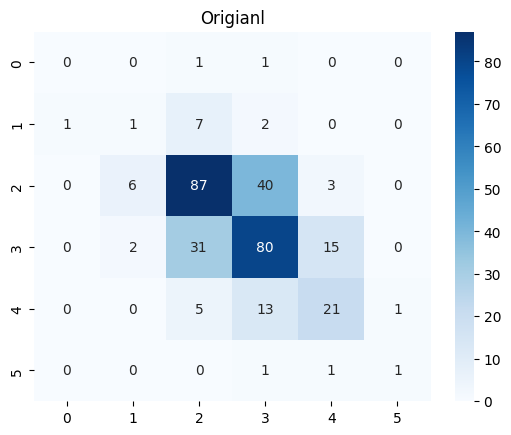

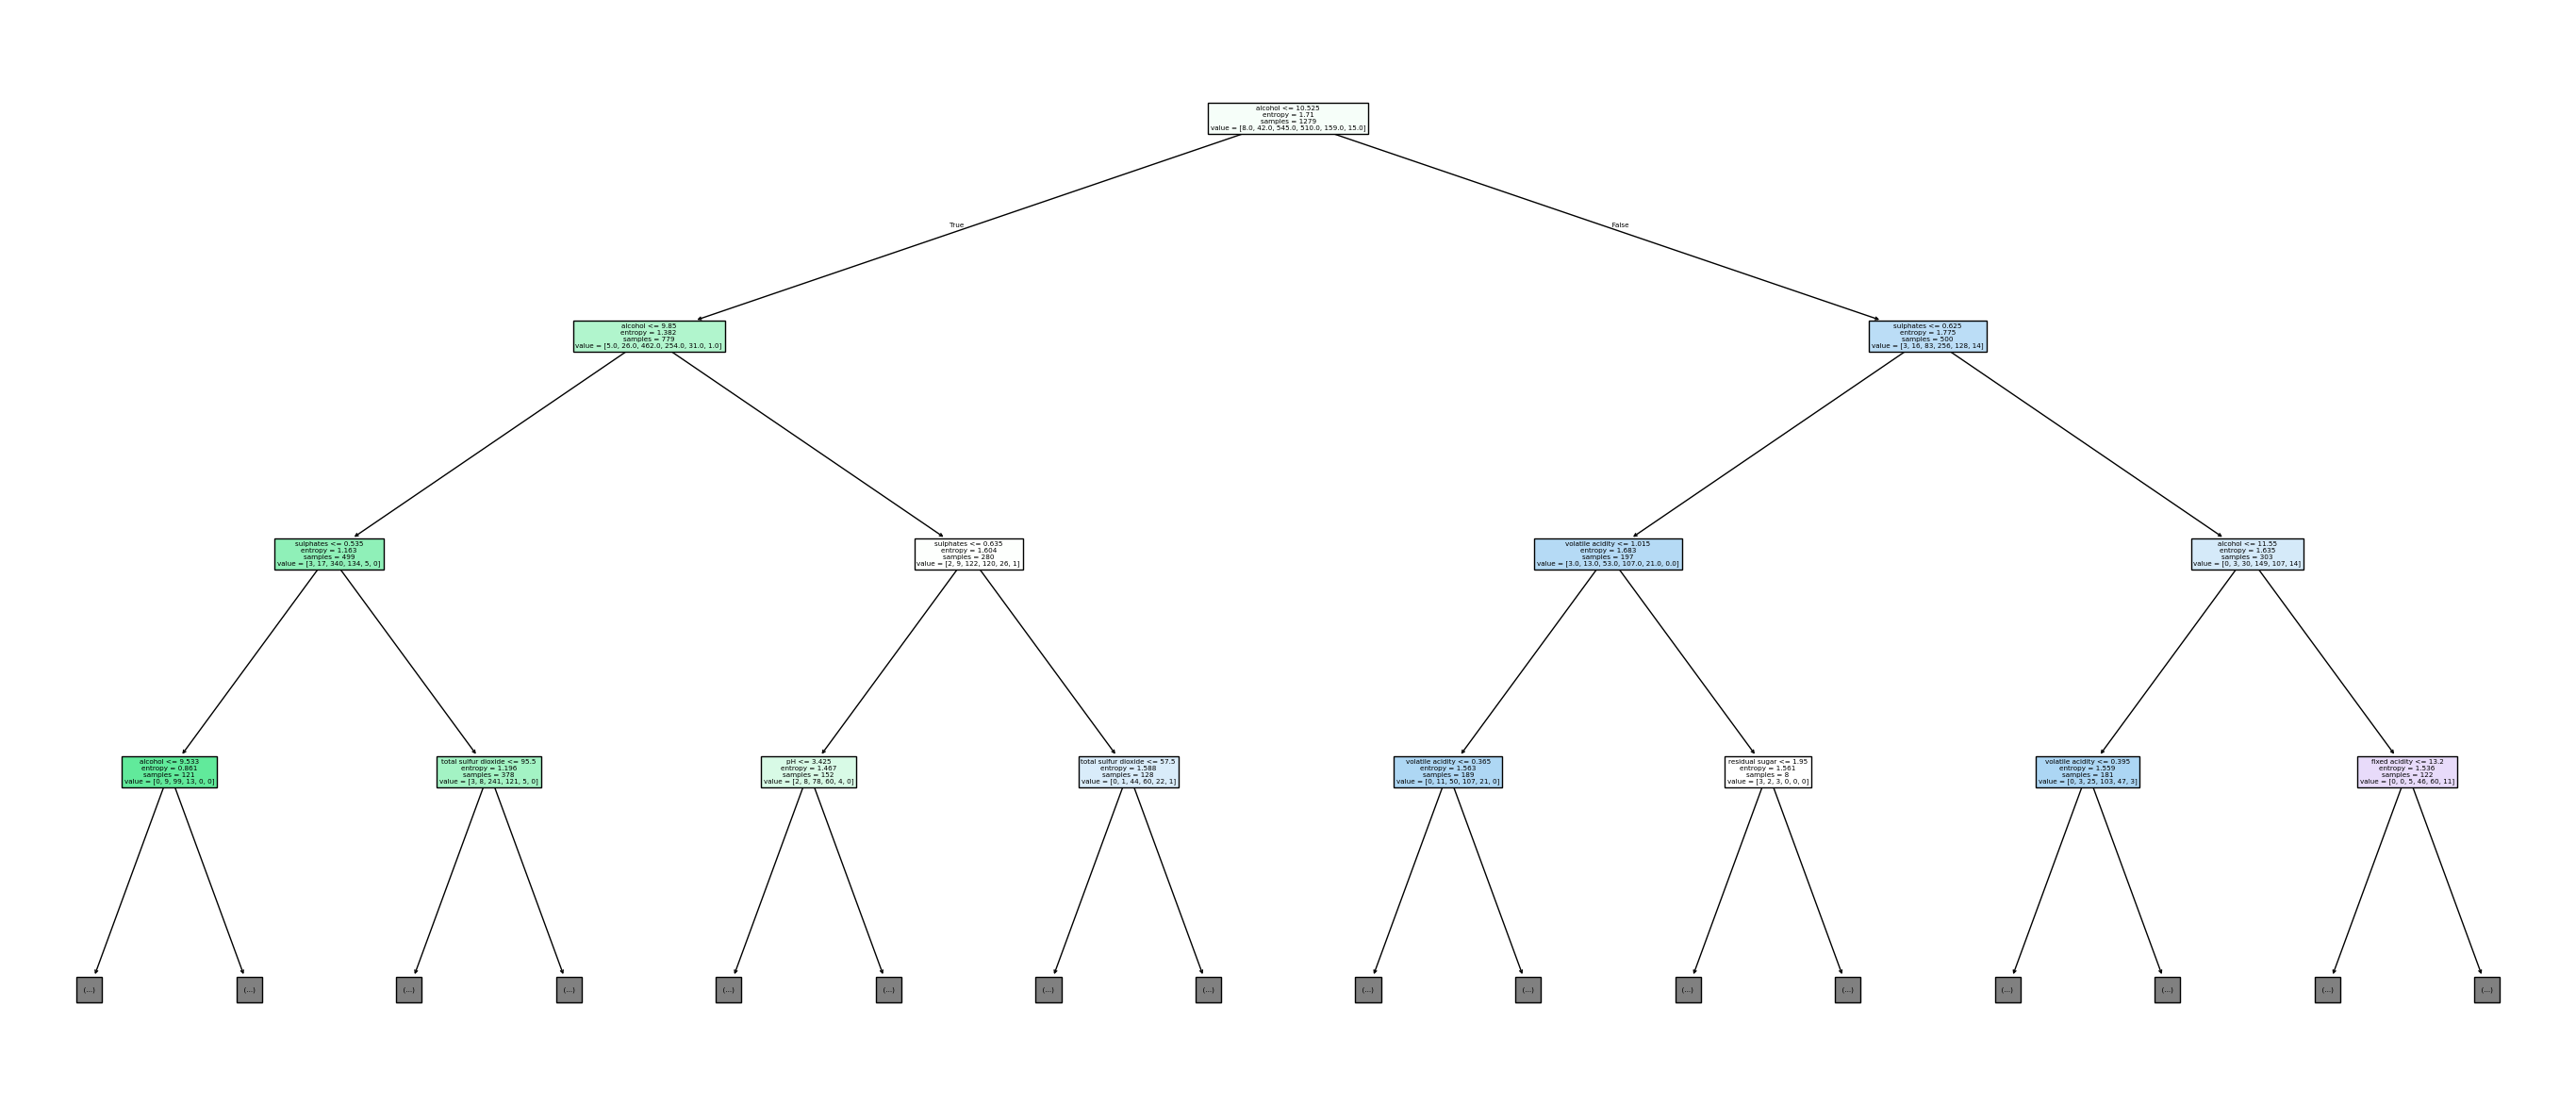

In [ ]:
tree=evaluate('Origianl',DecisionTreeClassifier(criterion='entropy', random_state=42))
plt.figure(figsize=(35,15))
plot_tree(tree,feature_names=X.columns,filled=True,max_depth=3)
plt.show()

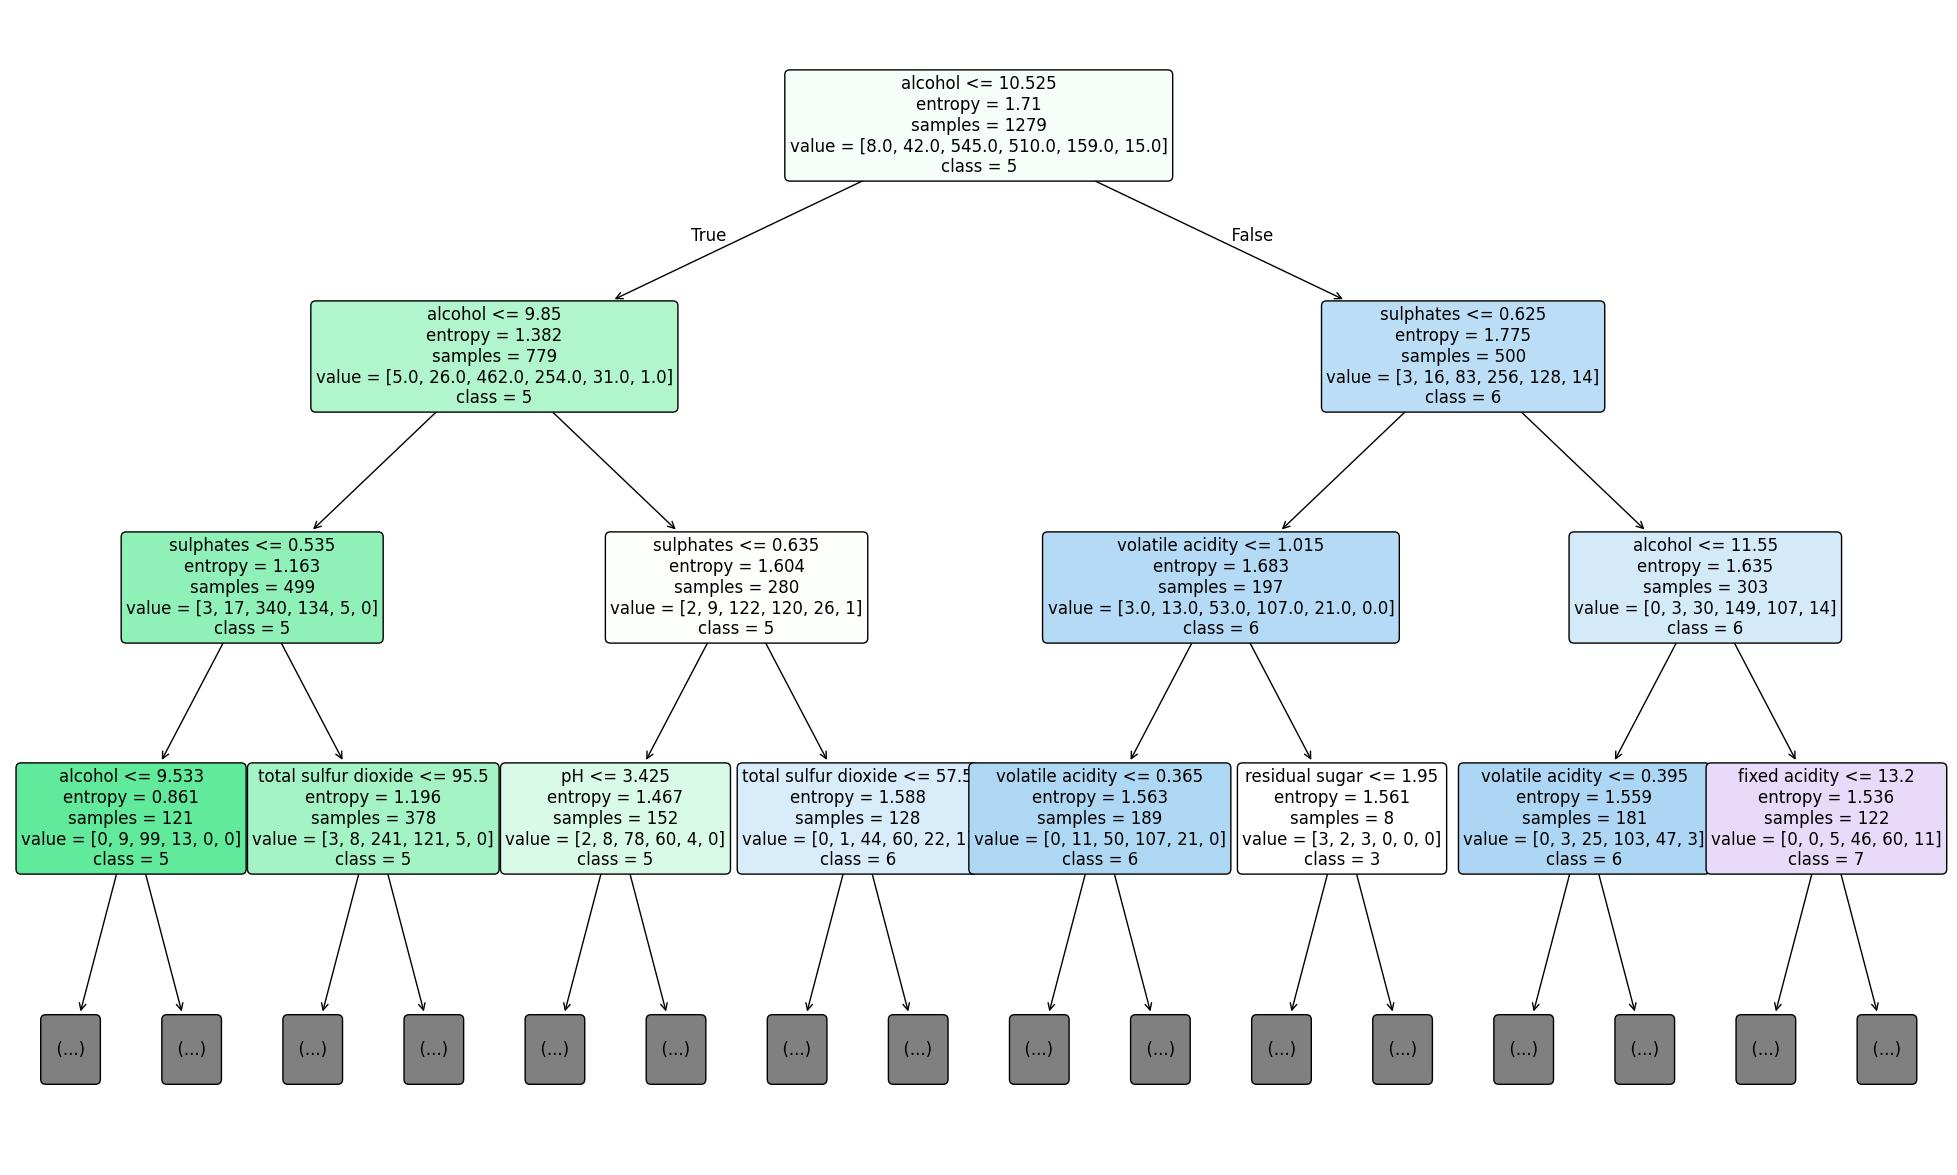

In [ ]:
plt.figure(figsize=(25,15))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=[str(i) for i in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=12,
    max_depth=3
)
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
model = DecisionTreeClassifier()

In [ ]:
importance=pd.Series(
    dt_model.feature_importances_,
    index=X.columns
    ).sort_values(ascending=False)

print(importance)

alcohol                 0.183838
sulphates               0.134306
volatile acidity        0.118186
total sulfur dioxide    0.098721
pH                      0.087091
chlorides               0.073129
density                 0.073024
residual sugar          0.062869
fixed acidity           0.058263
free sulfur dioxide     0.056880
citric acid             0.053693
dtype: float64


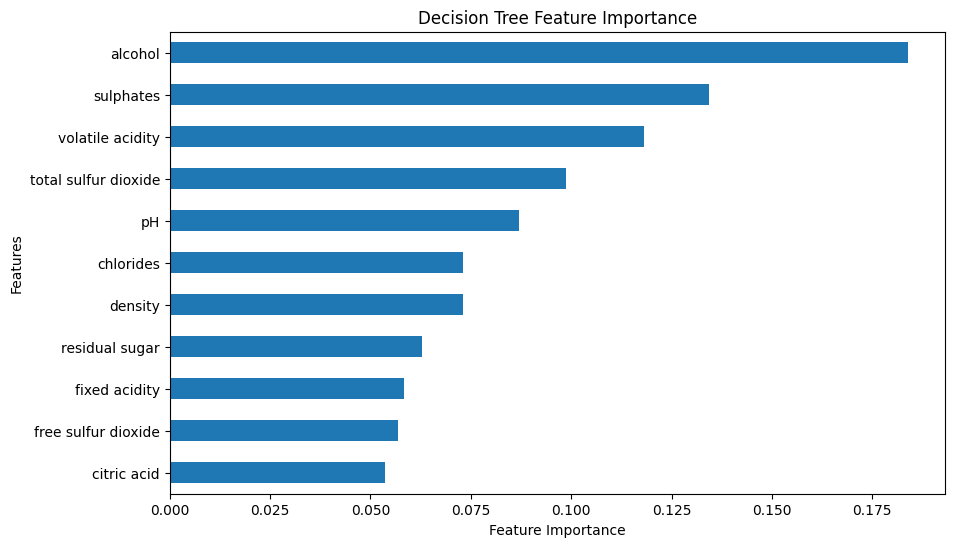

In [ ]:
plt.figure(figsize=(10,6))

importance.sort_values().plot(
    kind='barh',
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Decision Tree Feature Importance')
plt.show()

In [ ]:
print("Training Accuracy",dt_model.score(X_train,y_train))
print("Testing Accuracy",dt_model.score(X_test,y_test))

Training Accuracy 1.0
Testing Accuracy 0.60625


Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2,5,10,20],
    'min_samples_leaf': [1,2,4,8],
    'max_features':[None, 'sqrt','log2'],
    'ccp_alpha':[0,0.001,0.005,0.01]
}

grid=GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid,cv=5,scoring='accuracy',n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters")
print(grid.best_params_)
print("Best Cross Validation")
print(grid.best_score_)

best_tree=grid.best_estimator_

Best Parameters
{'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross Validation
0.6012500000000001


In [ ]:
y_pred=best_tree.predict(X_test)
print(classification_report(y_test,y_pred))
print("Accuracy =",accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.62      0.62       136
           6       0.56      0.55      0.56       128
           7       0.46      0.53      0.49        40
           8       0.00      0.00      0.00         3

    accuracy                           0.55       320
   macro avg       0.27      0.28      0.28       320
weighted avg       0.55      0.55      0.55       320

Accuracy = 0.546875


Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score

scores=cross_val_score(best_tree,X,y,cv=5,scoring='accuracy')
print(scores)
print("Avg Accuracy =",scores.mean())
print("Standard =",scores.std())

[0.46875    0.46875    0.521875   0.396875   0.50783699]
Avg Accuracy = 0.47281739811912227
Standard = 0.04343582725475413


Learning Curve

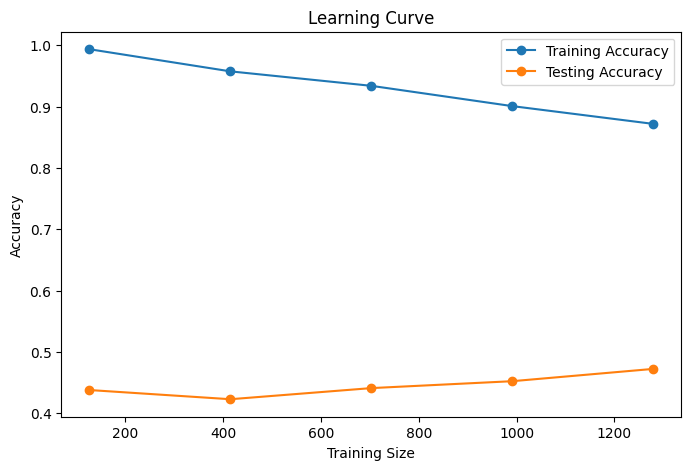

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes,train_scores,test_scores=learning_curve(best_tree,X,y,cv=5,scoring='accuracy')
plt.figure(figsize=(8,5))
plt.plot(train_sizes,train_scores.mean(axis=1),marker='o',label='Training Accuracy')
plt.plot(train_sizes,test_scores.mean(axis=1),marker='o',label='Testing Accuracy')
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.show()

Validation Curve

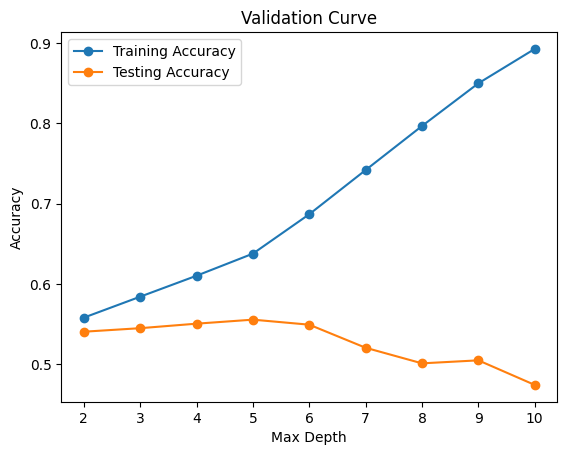

In [ ]:
from sklearn.model_selection import validation_curve

param_range=[2,3,4,5,6,7,8,9,10]
train_scores,test_scores=validation_curve(DecisionTreeClassifier(criterion='entropy',random_state=42),X,y,param_name='max_depth',param_range=param_range,cv=5)
plt .plot(param_range,train_scores.mean(axis=1),marker='o',label='Training Accuracy')
plt.plot(param_range,test_scores.mean(axis=1),marker='o',label='Testing Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.show()

Normalized Confusion Matrix

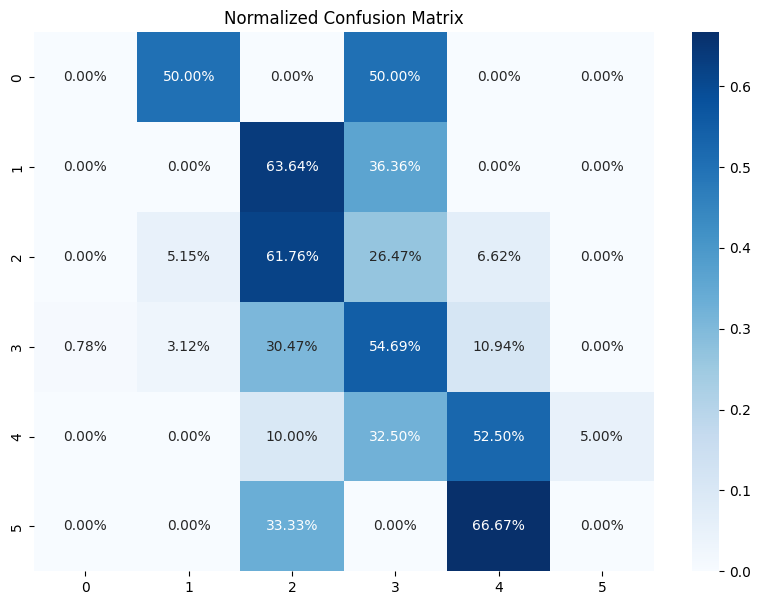

In [ ]:
cm=confusion_matrix(y_test,y_pred)
cm_percent=cm/cm.sum(axis=1,keepdims=True)
plt.figure(figsize=(10,7))
sns.heatmap(cm_percent,annot=True,fmt='.2%',cmap='Blues')
plt.title('Normalized Confusion Matrix')
plt.show()